# TP 8 — Méthodes d'ensemble : arbres de décision, forêts aléatoires, AdaBoost

**Cours :** *Ensemble Learning Methods* (slides 191–214) — arbres de décision (construction, critères d'arrêt, impureté, arbres profonds vs peu profonds), **bagging** et **forêts aléatoires** (analyse biais-variance, erreur **OOB**, importance des variables **MDI** et **MDA**), **boosting** et **AdaBoost** (construction, borne sur l'erreur d'apprentissage).

**À la fin de ce notebook, vous saurez :**
1. coder un arbre **CART** (régression et classification) avec une recherche de coupure vectorisée ;
2. coder une **forêt aléatoire**, son erreur **OOB** et les importances **MDI** / **MDA** ;
3. vérifier empiriquement la formule de variance d'une forêt $\rho\sigma^2 + (1-\rho)\sigma^2/B$ ;
4. coder **AdaBoost** avec des souches (*stumps*) et vérifier la borne sur l'erreur d'apprentissage ;
5. prédire des rendements en coupe transversale (*cross-section*) avec des interactions non linéaires, et éviter le piège classique de l'importance MDI.

> 📗 **Version corrigée.** Toutes les cellules s'exécutent de bout en bout.

In [1]:
import sys, pathlib, warnings
_here = pathlib.Path.cwd()
ROOT = _here.parent if _here.name in ("exercices", "corriges") else _here
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tp_utils import *          # style graphique, check(), check_close(), timer()...
import tp_data                  # données réelles (cache / téléchargement) ou simulées

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
rng = np.random.default_rng(42)
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, AdaBoostClassifier

## Partie 1 — Arbres de décision (CART, Breiman et al. 1984)

Un arbre est une **partition binaire de l'espace** (comme un k-d tree) : chaque nœud interne coupe selon une variable $s$ et un seuil $\theta$ ($x_s\le\theta$ à gauche), chaque feuille $t$ porte une prédiction constante $\hat y_t$ (moyenne en régression, proportions de classes en classification).

**Construction gloutonne** : à chaque nœud, choisir $(s,\theta)$ maximisant la **diminution d'impureté**
$$\Delta i = i(P) - \frac{\#P_L}{\#P}\,i(P_L) - \frac{\#P_R}{\#P}\,i(P_R),$$
avec $i$ = variance (régression), indice de **Gini** $1-\sum_c p_c^2$ ou **entropie** $-\sum_c p_c\log p_c$ (classification). On s'arrête si profondeur maximale atteinte, trop peu de points, ou aucun gain.

### Exercice 1.1 — Meilleure coupure, vectorisée

Pour une variable, triez les points ; les sommes cumulées donnent **en une passe** l'impureté de toutes les coupures possibles :
- régression : $\mathrm{SSE}_L = \sum_L y^2 - (\sum_L y)^2/n_L$ (idem à droite) et $n\,i = \mathrm{SSE}$ ;
- classification : comptes de classes cumulés → proportions → Gini.

Seuils : milieux entre deux valeurs **distinctes** consécutives ; chaque côté doit garder au moins `min_leaf` points.

In [2]:
def impurity(y, task, n_classes=None):
    if task == "regression":
        return float(np.var(y)) if len(y) else 0.0
    p = np.bincount(y, minlength=n_classes) / len(y)
    return float(1 - (p ** 2).sum())


def best_split(X, y, task, features, min_leaf=1, n_classes=None):
    """Retourne (variable, seuil, gain Δi) ; variable = None si aucune coupure valide."""
    n = len(y)
    parent = impurity(y, task, n_classes)
    best = (None, None, 0.0)
    nL = np.arange(1, n); nR = n - nL
    for j in features:
        order = np.argsort(X[:, j], kind="stable")
        xs, ys = X[order, j], y[order]
        if task == "regression":
            cs, cs2 = np.cumsum(ys)[:-1], np.cumsum(ys ** 2)[:-1]
            tot, tot2 = ys.sum(), (ys ** 2).sum()
            sseL = cs2 - cs ** 2 / nL
            sseR = (tot2 - cs2) - (tot - cs) ** 2 / nR
            child = (sseL + sseR) / n
        else:
            C = np.cumsum(np.eye(n_classes)[ys], axis=0)[:-1]
            tot = np.bincount(ys, minlength=n_classes)
            gL = 1 - ((C / nL[:, None]) ** 2).sum(1)
            gR = 1 - (((tot - C) / nR[:, None]) ** 2).sum(1)
            child = (nL * gL + nR * gR) / n
        valid = (xs[1:] > xs[:-1]) & (nL >= min_leaf) & (nR >= min_leaf)
        if not valid.any():
            continue
        k = int(np.argmin(np.where(valid, child, np.inf)))
        gain = parent - child[k]
        if gain > best[2] + 1e-15:
            best = (j, 0.5 * (xs[k] + xs[k + 1]), gain)
    return best

In [3]:
# Test : comparaison avec une recherche exhaustive naïve
Xs = rng.normal(size=(60, 3)); ys = Xs[:, 1] ** 2 + rng.normal(0, 0.1, 60)
def naive_best(X, y):
    best = (None, None, 0.0)
    for j in range(X.shape[1]):
        v = np.unique(X[:, j])
        for t in (v[:-1] + v[1:]) / 2:
            L, R = y[X[:, j] <= t], y[X[:, j] > t]
            g = np.var(y) - len(L) / len(y) * np.var(L) - len(R) / len(y) * np.var(R)
            if g > best[2]:
                best = (j, t, g)
    return best
j, t, g = best_split(Xs, ys, "regression", range(3))
jn, tn, gn = naive_best(Xs, ys)
check(j == jn and np.isclose(t, tn) and np.isclose(g, gn), f"best_split = recherche exhaustive (variable {j}, seuil {t:.3f})")

✅ best_split = recherche exhaustive (variable 1, seuil 2.258)


### Exercice 1.2 — Construction récursive et prédiction

Chaque nœud est un `dict`. On accumule aussi l'**importance MDI** de l'arbre : pour chaque coupure, on ajoute $\frac{\#t}{n}\,\Delta i(t)$ à la variable utilisée.
`max_features` = nombre de variables tirées au hasard à chaque nœud (toutes par défaut ; c'est la clé des forêts aléatoires).

In [4]:
def build_tree(X, y, task="regression", max_depth=None, min_leaf=1, max_features=None,
               n_classes=None, rng=None):
    n, d = X.shape
    rng = rng or np.random.default_rng(0)
    if task == "classification" and n_classes is None:
        n_classes = int(y.max()) + 1
    m = d if max_features is None else max_features
    importances = np.zeros(d)

    def leaf(idx):
        if task == "regression":
            return {"leaf": True, "value": float(y[idx].mean())}
        return {"leaf": True, "value": np.bincount(y[idx], minlength=n_classes) / len(idx)}

    def grow(idx, depth):
        if (max_depth is not None and depth >= max_depth) or len(idx) < 2 * min_leaf \
                or impurity(y[idx], task, n_classes) == 0:
            return leaf(idx)
        feats = rng.choice(d, m, replace=False) if m < d else range(d)
        j, thr, gain = best_split(X[idx], y[idx], task, feats, min_leaf, n_classes)
        if j is None:
            return leaf(idx)
        importances[j] += len(idx) / n * gain
        mask = X[idx, j] <= thr
        return {"leaf": False, "feature": j, "threshold": thr,
                "left": grow(idx[mask], depth + 1), "right": grow(idx[~mask], depth + 1)}

    root = grow(np.arange(n), 0)
    return {"root": root, "task": task, "n_classes": n_classes, "mdi": importances}


def predict_tree(tree, X):
    """Régression : (m,) ; classification : (m, n_classes) probabilités."""
    shape = (len(X),) if tree["task"] == "regression" else (len(X), tree["n_classes"])
    out = np.empty(shape)

    def route(node, idx):
        if node["leaf"]:
            out[idx] = node["value"]
            return
        mask = X[idx, node["feature"]] <= node["threshold"]
        route(node["left"], idx[mask]); route(node["right"], idx[~mask])

    route(tree["root"], np.arange(len(X)))
    return out

In [5]:
# Tests vs scikit-learn (mêmes critères, seuils au milieu)
X = rng.normal(size=(400, 4)); y = np.sin(X[:, 0]) + X[:, 1] * (X[:, 2] > 0) + rng.normal(0, 0.2, 400)
Xq = rng.normal(size=(200, 4))
for depth in [2, 5]:
    ours = predict_tree(build_tree(X, y, max_depth=depth), Xq)
    sk = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(X, y).predict(Xq)
    check_close(ours, sk, f"arbre de régression (profondeur {depth}) = sklearn")
yc = (X[:, 0] + X[:, 1] ** 2 > 0.5).astype(int)
# (au-delà de quelques niveaux, des coupures ex aequo peuvent être départagées différemment)
ours = predict_tree(build_tree(X, yc, "classification", max_depth=3), Xq)
sk = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X, yc).predict_proba(Xq)
check_close(ours, sk, "arbre de classification (Gini) = sklearn")

✅ arbre de régression (profondeur 2) = sklearn
✅ arbre de régression (profondeur 5) = sklearn
✅ arbre de classification (Gini) = sklearn


### Expérience 1.3 — Arbres profonds vs peu profonds

Biais et variance d'un arbre, estimés sur 50 jeux d'apprentissage indépendants (régression 1D).

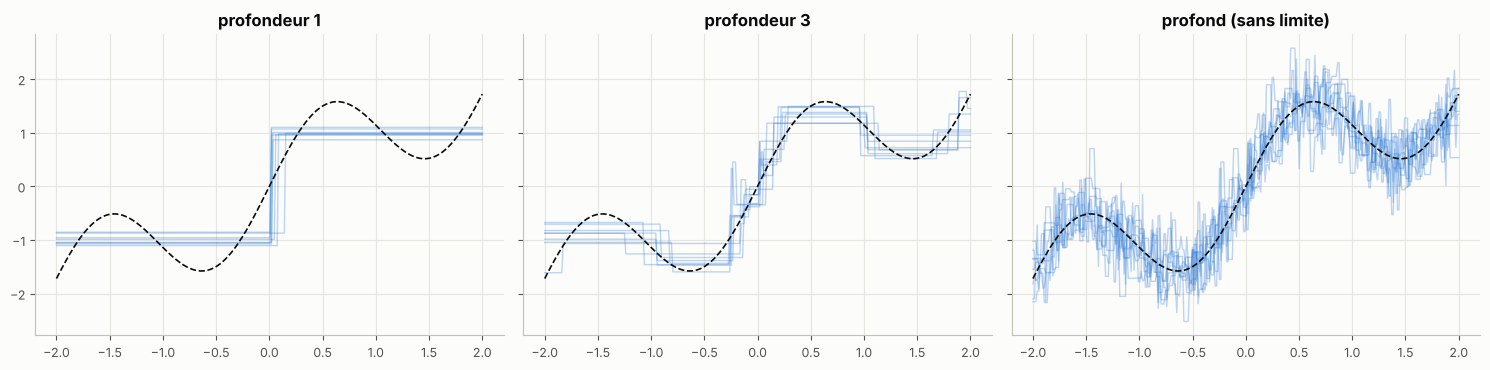

,biais²,variance
arbre,,
profondeur 1,0.1404,0.0479
profondeur 3,0.0279,0.0558
profond (sans limite),0.0040,0.1573


In [6]:
f1 = lambda x: np.sin(3 * x) + x
xs_grid = np.linspace(-2, 2, 300)[:, None]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
stats_rows = []
for ax, depth in zip(axes, [1, 3, None]):
    preds = []
    for s in range(50):
        r_ = np.random.default_rng(s)
        x = r_.uniform(-2, 2, (150, 1)); yy = f1(x[:, 0]) + r_.normal(0, 0.4, 150)
        preds.append(predict_tree(build_tree(x, yy, max_depth=depth), xs_grid))
    P = np.array(preds)
    for p in P[:8]:
        ax.plot(xs_grid[:, 0], p, color=BLUE, alpha=0.3, lw=1)
    ax.plot(xs_grid[:, 0], f1(xs_grid[:, 0]), color=INK, ls="--", lw=1.2)
    label = "profond (sans limite)" if depth is None else f"profondeur {depth}"
    ax.set_title(label)
    stats_rows.append((label, ((P.mean(0) - f1(xs_grid[:, 0])) ** 2).mean(), P.var(0).mean()))
plt.tight_layout(); plt.show()
pd.DataFrame(stats_rows, columns=["arbre", "biais²", "variance"]).set_index("arbre")

**Arbres peu profonds** : biais fort, variance faible → *apprenants faibles*, à **booster**. **Arbres profonds** : biais faible, variance forte → à **moyenner** (bagging).

## Partie 2 — Bagging et forêts aléatoires (Breiman 2001)

Pour $b = 1..B$ : tirer un **échantillon bootstrap** $Z_b$ (taille $n$, avec remise), construire un arbre **profond** sur $Z_b$ en ne considérant, à chaque nœud, qu'un sous-ensemble aléatoire de $m < d$ variables. Prédire par la **moyenne** (régression) ou le **vote** / la moyenne des probabilités (classification).

Chaque point est absent d'environ $(1-1/n)^n\approx 36{,}8\,\%$ des échantillons bootstrap : les arbres qui ne l'ont pas vu fournissent une prédiction **out-of-bag** (OOB), d'où une estimation de l'erreur de test **gratuite**.

### Exercice 2.1 — `random_forest_fit` et prédiction

In [7]:
def random_forest_fit(X, y, task="regression", B=100, max_features=None, min_leaf=1, max_depth=None, seed=0):
    rr = np.random.default_rng(seed)
    n = len(y)
    n_classes = int(y.max()) + 1 if task == "classification" else None
    trees, oob = [], []
    for b in range(B):
        idx = rr.integers(0, n, n)
        mask = np.ones(n, bool); mask[idx] = False
        tree = build_tree(X[idx], y[idx], task, max_depth=max_depth, min_leaf=min_leaf,
                          max_features=max_features, n_classes=n_classes, rng=rr)
        trees.append(tree); oob.append(np.where(mask)[0])
    return {"trees": trees, "oob": oob, "task": task, "n_classes": n_classes, "n": n}


def forest_predict(forest, X, n_trees=None):
    """Moyenne des prédictions des n_trees premiers arbres (probabilités en classification)."""
    trees = forest["trees"][:n_trees]
    return np.mean([predict_tree(t, X) for t in trees], axis=0)

### Exercice 2.2 — Erreur OOB

In [8]:
def oob_prediction(forest, X):
    """Prédiction OOB de chaque point d'apprentissage (NaN si jamais OOB)."""
    n = forest["n"]
    shape = (n,) if forest["task"] == "regression" else (n, forest["n_classes"])
    acc, cnt = np.zeros(shape), np.zeros(n)
    for t, o in zip(forest["trees"], forest["oob"]):
        if len(o):
            acc[o] += predict_tree(t, X[o]); cnt[o] += 1
    with np.errstate(invalid="ignore"):
        return acc / (cnt if forest["task"] == "regression" else cnt[:, None])

In [9]:
# Test : l'erreur OOB estime bien l'erreur de test
fX = lambda X: np.sin(2 * X[:, 0]) + X[:, 1] * X[:, 2] + 0.5 * (X[:, 3] > 0)
Xtr = rng.normal(size=(500, 6)); ytr = fX(Xtr) + rng.normal(0, 0.3, 500)
Xte = rng.normal(size=(3000, 6)); yte = fX(Xte) + rng.normal(0, 0.3, 3000)
with timer("forêt de 100 arbres"):
    rf = random_forest_fit(Xtr, ytr, B=100, max_features=2, min_leaf=2)
oob_mse = np.nanmean((oob_prediction(rf, Xtr) - ytr) ** 2)
test_mse = np.mean((forest_predict(rf, Xte) - yte) ** 2)
tree_mse = np.mean((predict_tree(build_tree(Xtr, ytr, min_leaf=2), Xte) - yte) ** 2)
print(f"MSE : arbre seul {tree_mse:.3f} | forêt (test) {test_mse:.3f} | forêt (OOB) {oob_mse:.3f}")
check(abs(oob_mse - test_mse) / test_mse < 0.25, "OOB ≈ erreur de test")
check(test_mse < 0.85 * tree_mse, "la forêt réduit nettement l'erreur d'un arbre profond")

⏱  forêt de 100 arbres : 2.070 s
MSE : arbre seul 1.370 | forêt (test) 0.981 | forêt (OOB) 0.964
✅ OOB ≈ erreur de test
✅ la forêt réduit nettement l'erreur d'un arbre profond


### Expérience 2.3 — Variance d'une forêt : $\rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$

Si chaque arbre a une variance $\sigma^2$ et deux arbres ont une corrélation $\rho$ (ils voient les mêmes données), la moyenne de $B$ arbres a une variance $\rho\sigma^2 + (1-\rho)\sigma^2/B$ : **elle ne descend pas sous $\rho\sigma^2$**. Le biais, lui, reste celui d'un arbre. Tirer $m<d$ variables par nœud **décorrèle** les arbres (baisse $\rho$) — c'est tout l'apport des forêts aléatoires par rapport au bagging ($m = d$).

On mesure la variance de la prédiction (sur 20 points fixes) à travers 15 jeux d'apprentissage.

⏱  expérience de variance : 18.891 s


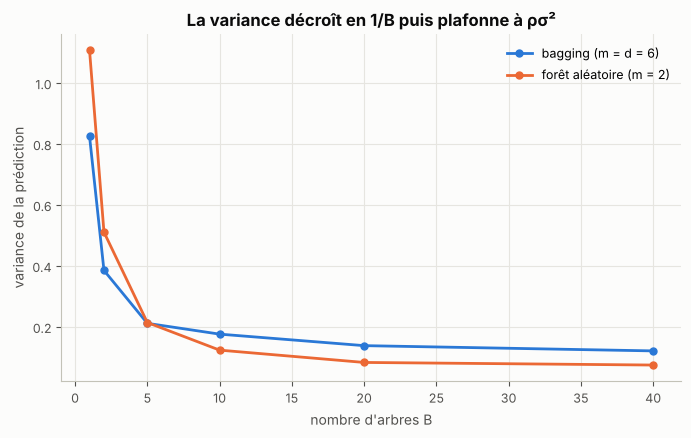

✅ décorréler les arbres réduit le plancher de variance


In [10]:
Bs = [1, 2, 5, 10, 20, 40]
x_fix = rng.normal(size=(20, 6))
res_var = {}
with timer("expérience de variance"):
    for name, m in [("bagging (m = d = 6)", None), ("forêt aléatoire (m = 2)", 2)]:
        P = []
        for s in range(15):
            r_ = np.random.default_rng(100 + s)
            X_ = r_.normal(size=(300, 6)); y_ = fX(X_) + r_.normal(0, 0.3, 300)
            f_ = random_forest_fit(X_, y_, B=max(Bs), max_features=m, min_leaf=2, seed=s)
            per_tree = np.array([predict_tree(t, x_fix) for t in f_["trees"]])   # (B, 20)
            P.append([per_tree[:b].mean(0) for b in Bs])
        P = np.array(P)                                                          # (sets, len(Bs), 20)
        res_var[name] = P.var(0).mean(1)
fig, ax = plt.subplots()
for i, (name, v) in enumerate(res_var.items()):
    ax.plot(Bs, v, marker="o", color=PALETTE[i], label=name)
ax.set_xlabel("nombre d'arbres B"); ax.set_ylabel("variance de la prédiction")
ax.set_title("La variance décroît en 1/B puis plafonne à ρσ²"); ax.legend()
plt.show()
check(res_var["forêt aléatoire (m = 2)"][-1] < res_var["bagging (m = d = 6)"][-1], "décorréler les arbres réduit le plancher de variance")

### Exercice 2.4 — Importance des variables : MDI et MDA

- **MDI** (*mean decrease in impurity*) : moyenne sur les arbres de $\sum_{t:\,\text{coupe sur }s}\frac{\#t}{n}\Delta i(t)$ — déjà accumulée dans `tree["mdi"]`. Gratuite, mais **biaisée** : elle favorise les variables continues à nombreuses valeurs, même non informatives (beaucoup de seuils possibles → on trouve toujours une coupure qui réduit un peu l'impureté sur l'échantillon d'apprentissage).
- **MDA** (*mean decrease in accuracy*, importance par permutation) : pour chaque arbre, erreur OOB après **permutation** de la colonne $s$ moins erreur OOB d'origine, moyennée sur les arbres. Plus coûteuse, mais mesurée **hors échantillon**.

In [11]:
def mdi_importance(forest):
    imp = np.mean([t["mdi"] for t in forest["trees"]], axis=0)
    return imp / imp.sum()


def mda_importance(forest, X, y, seed=0):
    """Augmentation moyenne de l'erreur OOB (MSE ou taux d'erreur) quand on permute chaque variable."""
    rr = np.random.default_rng(seed)
    d = X.shape[1]
    def err(tree, Xo, yo):
        p = predict_tree(tree, Xo)
        return np.mean((p - yo) ** 2) if forest["task"] == "regression" else np.mean(p.argmax(1) != yo)
    out = np.zeros(d)
    for t, o in zip(forest["trees"], forest["oob"]):
        if len(o) == 0:
            continue
        Xo, yo = X[o], y[o]
        base = err(t, Xo, yo)
        for j in range(d):
            Xp = Xo.copy(); Xp[:, j] = rr.permutation(Xp[:, j])
            out[j] += err(t, Xp, yo) - base
    return out / len(forest["trees"])

In [12]:
# Test : seules les variables 0 à 3 entrent dans fX ; 4 et 5 sont du bruit
mdi, mda = mdi_importance(rf), mda_importance(rf, Xtr, ytr)
check(mda[:4].min() > mda[4:].max(), "MDA : les variables utiles dominent le bruit")
pd.DataFrame({"MDI": mdi, "MDA": mda}, index=[f"x{j}" for j in range(6)])

✅ MDA : les variables utiles dominent le bruit


,MDI,MDA
x0,0.3782,0.8246
x1,0.1972,0.2948
x2,0.1953,0.1817
x3,0.0906,0.0365
x4,0.0663,-0.0275
x5,0.0724,-0.0317


## Partie 3 — Boosting et AdaBoost (Freund & Schapire 1995)

Le boosting entraîne des **apprenants faibles** (biais fort, variance faible : souches = arbres de profondeur 1) **séquentiellement**, chacun sur les données **repondérées** pour insister sur les erreurs des précédents. Avec $y\in\{-1,1\}$ :
- $\mu_1(x_i) = 1/n$ ;
- pour $b = 1..B$ : entraîner $T_b$ sur les poids $\mu_b$, erreur pondérée $e_b = \sum_i\mu_b(x_i)\mathbb 1_{y_i\ne T_b(x_i)}$, poids $\alpha_b = \frac12\ln\frac{1-e_b}{e_b}$, puis $\mu_{b+1}(x_i)\propto\mu_b(x_i)\,e^{-\alpha_by_iT_b(x_i)}$ ;
- prédiction : $\mathrm{sign}\big(\sum_b\alpha_bT_b(x)\big)$.

**Théorème** : l'erreur d'apprentissage est majorée par $\prod_b 2\sqrt{e_b(1-e_b)}$, qui décroît **exponentiellement** tant que chaque $e_b<1/2-\gamma$.

### Exercice 3.1 — Souche pondérée
Pour chaque variable et chaque seuil, la souche prédit $+s$ si $x_j>\theta$ et $-s$ sinon ($s=\pm1$). Avec les poids triés et cumulés, l'erreur pondérée de toutes les coupures s'obtient en une passe :
$e(s{=}{+}1) = \sum_{\text{gauche}}\mu\,\mathbb 1_{y=+1} + \sum_{\text{droite}}\mu\,\mathbb 1_{y=-1}$ et $e(s{=}{-}1) = 1 - e(s{=}{+}1)$ (poids normalisés).

In [13]:
def fit_stump(X, y, w):
    """Retourne (variable, seuil, s, erreur pondérée) minimisant l'erreur pondérée."""
    best = (0, 0.0, 1, np.inf)
    for j in range(X.shape[1]):
        order = np.argsort(X[:, j], kind="stable")
        xs, ys, ws = X[order, j], y[order], w[order]
        pos_left = np.cumsum(ws * (ys == 1))[:-1]
        neg_left = np.cumsum(ws * (ys == -1))[:-1]
        neg_tot = (ws * (ys == -1)).sum()
        err_plus = pos_left + (neg_tot - neg_left)
        err_minus = w.sum() - err_plus
        valid = xs[1:] > xs[:-1]
        if not valid.any():
            continue
        for s, e in [(1, err_plus), (-1, err_minus)]:
            e = np.where(valid, e, np.inf); k = int(np.argmin(e))
            if e[k] < best[3]:
                best = (j, 0.5 * (xs[k] + xs[k + 1]), s, float(e[k]))
    return best


def stump_predict(stump, X):
    j, thr, s, _ = stump
    return np.where(X[:, j] > thr, s, -s)

In [14]:
# Test : comparaison avec une recherche exhaustive
Xb = rng.normal(size=(40, 2)); yb = np.where(Xb[:, 0] + 0.3 * rng.normal(size=40) > 0, 1, -1); wb = rng.random(40); wb /= wb.sum()
st = fit_stump(Xb, yb, wb)
brute = min(((j, t, s) for j in range(2) for t in np.unique(Xb[:, j]) for s in (1, -1)),
            key=lambda c: (wb * (np.where(Xb[:, c[0]] > c[1], c[2], -c[2]) != yb)).sum())
e_brute = (wb * (np.where(Xb[:, brute[0]] > brute[1], brute[2], -brute[2]) != yb)).sum()
check(np.isclose(st[3], e_brute), f"souche optimale (erreur pondérée {st[3]:.3f})")

✅ souche optimale (erreur pondérée 0.091)


### Exercice 3.2 — AdaBoost

In [15]:
def adaboost_fit(X, y, B=100):
    n = len(y)
    w = np.full(n, 1 / n)
    stumps, alphas, errors = [], [], []
    for b in range(B):
        st = fit_stump(X, y, w)
        pred = stump_predict(st, X)
        e = np.clip(np.sum(w * (pred != y)), 1e-12, 1 - 1e-12)
        a = 0.5 * np.log((1 - e) / e)
        w = w * np.exp(-a * y * pred); w /= w.sum()
        stumps.append(st); alphas.append(a); errors.append(e)
    return {"stumps": stumps, "alphas": np.array(alphas), "errors": np.array(errors)}


def adaboost_score(model, X, n_rounds=None):
    k = n_rounds or len(model["stumps"])
    return sum(a * stump_predict(s, X) for s, a in zip(model["stumps"][:k], model["alphas"][:k]))

✅ erreur d'apprentissage ≤ ∏ 2√(e_b(1−e_b)) à chaque étape


erreur de test : notre AdaBoost 0.256 | sklearn 0.237 | Bayes 0.211


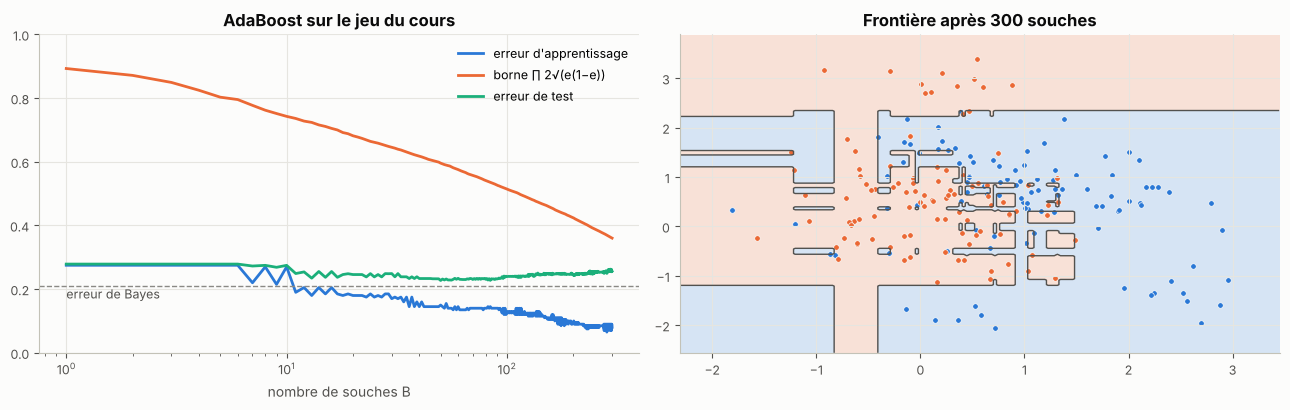

In [16]:
mix = tp_data.ESLMixture()
Xa, ya01 = mix.sample(100, seed=1); ya = 2 * ya01 - 1
Xt, yt01 = mix.sample(5000, seed=2); yt = 2 * yt01 - 1
ada = adaboost_fit(Xa, ya, B=300)
rounds = np.arange(1, 301)
train_err = [np.mean(np.sign(adaboost_score(ada, Xa, k)) != ya) for k in rounds]
test_err = [np.mean(np.sign(adaboost_score(ada, Xt, k)) != yt) for k in rounds]
bound = np.cumprod(2 * np.sqrt(ada["errors"] * (1 - ada["errors"])))
check(np.all(np.array(train_err) <= bound + 1e-12), "erreur d'apprentissage ≤ ∏ 2√(e_b(1−e_b)) à chaque étape")
sk_ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=300, random_state=0).fit(Xa, ya)
print(f"erreur de test : notre AdaBoost {test_err[-1]:.3f} | sklearn {1 - sk_ada.score(Xt, yt):.3f} | Bayes {mix.bayes_error():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].semilogx(rounds, train_err, label="erreur d'apprentissage")
axes[0].semilogx(rounds, bound, label="borne ∏ 2√(e(1−e))")
axes[0].semilogx(rounds, test_err, label="erreur de test")
axes[0].axhline(mix.bayes_error(), color=GRAY, ls="--", lw=1)
axes[0].text(1, mix.bayes_error() - 0.04, "erreur de Bayes", color=INK2, fontsize=9)
axes[0].set_xlabel("nombre de souches B"); axes[0].set_ylim(0, 1); axes[0].legend(); axes[0].set_title("AdaBoost sur le jeu du cours")
plot_decision_boundary(axes[1], lambda Z: np.sign(adaboost_score(ada, Z)), Xa, ya, "Frontière après 300 souches")
plt.tight_layout(); plt.show()

## Partie 4 — Application : prédire des rendements en coupe transversale

Le problème central d'un fonds *equity* quantitatif : chaque mois, classer ~1000 actions selon leur rendement attendu à partir de **caractéristiques** (momentum, valorisation, taille, volatilité, retournement…), acheter le haut du classement et vendre le bas. Les relations sont **faibles** et souvent **non linéaires** (effets conditionnels, interactions) — terrain de jeu des arbres (Gu, Kelly & Xiu, *Empirical Asset Pricing via Machine Learning*, 2020).

**Panel simulé** (40 mois × 400 actions) — vérité connue :
- le **momentum** ne paie que pour les actions **peu volatiles** (interaction) ;
- la **valeur** paie linéairement, le **retournement** (rendement du dernier mois) est négatif, la **taille** a un effet en U ;
- deux variables de **bruit pur** : une continue, une binaire ;
- rapport signal/bruit très faible ($R^2$ ≈ 3 %).

On apprend sur les 30 premiers mois, on teste sur les 10 derniers. (Sur données réelles, un IC mensuel de 0,02–0,05 est déjà un bon signal ; on a pris ici un signal plus fort pour que les différences soient lisibles avec peu de données.) Mesures : **IC** mensuel moyen (corrélation de rang prédiction/réalisé) et rendement d'un portefeuille **long-short** décile haut − décile bas.

In [17]:
def simulate_panel(n_months=40, n_stocks=400, seed=0):
    r_ = np.random.default_rng(seed)
    rows = []
    for t in range(n_months):
        F = pd.DataFrame({"momentum": r_.normal(size=n_stocks), "value": r_.normal(size=n_stocks),
                          "size": r_.normal(size=n_stocks), "volatility": r_.normal(size=n_stocks),
                          "reversal": r_.normal(size=n_stocks),
                          "bruit_continu": r_.normal(size=n_stocks), "bruit_binaire": r_.integers(0, 2, n_stocks)})
        mu = (0.6 * F["momentum"] * (F["volatility"] < 0) + 0.3 * F["value"] - 0.3 * F["reversal"]
              + 0.25 * (F["size"] ** 2 - 1))
        F["ret"] = mu + r_.normal(0, 3.0, n_stocks)
        F["month"] = t
        rows.append(F)
    return pd.concat(rows, ignore_index=True)

panel = simulate_panel()
feats = ["momentum", "value", "size", "volatility", "reversal", "bruit_continu", "bruit_binaire"]
tr, te = panel[panel.month < 30], panel[panel.month >= 30]
Xp_tr, yp_tr, Xp_te = tr[feats].to_numpy(float), tr["ret"].to_numpy(), te[feats].to_numpy(float)
print("observations d'apprentissage :", len(tr), "| de test :", len(te))

observations d'apprentissage : 12000 | de test : 4000


### Exercice 4.1 — OLS vs forêt aléatoire

Sur données financières bruitées, on utilise des feuilles **larges** (`min_leaf` ≈ 50–100) : un arbre « profond » au sens habituel ne ferait qu'apprendre le bruit.

In [18]:
def evaluate(pred, df):
    df = df.assign(pred=pred)
    ic = df.groupby("month").apply(lambda g: g["pred"].rank().corr(g["ret"].rank()), include_groups=False)
    def ls(g):
        q = g["pred"].rank(pct=True)
        return g.loc[q > 0.9, "ret"].mean() - g.loc[q <= 0.1, "ret"].mean()
    lsr = df.groupby("month").apply(ls, include_groups=False)
    return {"IC moyen": ic.mean(), "t(IC)": ic.mean() / ic.std() * np.sqrt(len(ic)), "long-short moyen": lsr.mean()}

Xi_tr = np.c_[np.ones(len(Xp_tr)), Xp_tr]
beta = np.linalg.lstsq(Xi_tr, yp_tr, rcond=None)[0]
pred_ols = np.c_[np.ones(len(Xp_te)), Xp_te] @ beta
with timer("forêt"):
    rf_p = random_forest_fit(Xp_tr, yp_tr, B=60, max_features=3, min_leaf=80, seed=0)
pred_rf = forest_predict(rf_p, Xp_te)
true_mu = (0.6 * te["momentum"] * (te["volatility"] < 0) + 0.3 * te["value"] - 0.3 * te["reversal"] + 0.25 * (te["size"] ** 2 - 1))
perf = pd.DataFrame({"OLS": evaluate(pred_ols, te), "forêt aléatoire": evaluate(pred_rf, te),
                     "oracle (vraie espérance)": evaluate(true_mu.to_numpy(), te)}).T
check(perf.loc["forêt aléatoire", "IC moyen"] > perf.loc["OLS", "IC moyen"], "la forêt capte les non-linéarités ignorées par l'OLS")
perf

⏱  forêt : 2.812 s
✅ la forêt capte les non-linéarités ignorées par l'OLS


,IC moyen,t(IC),long-short moyen
OLS,0.1343,9.0860,1.4367
forêt aléatoire,0.1497,7.6934,1.8930
oracle (vraie espérance),0.1777,10.7871,2.2214


### Exercice 4.2 — Quelles variables comptent ? MDI vs MDA

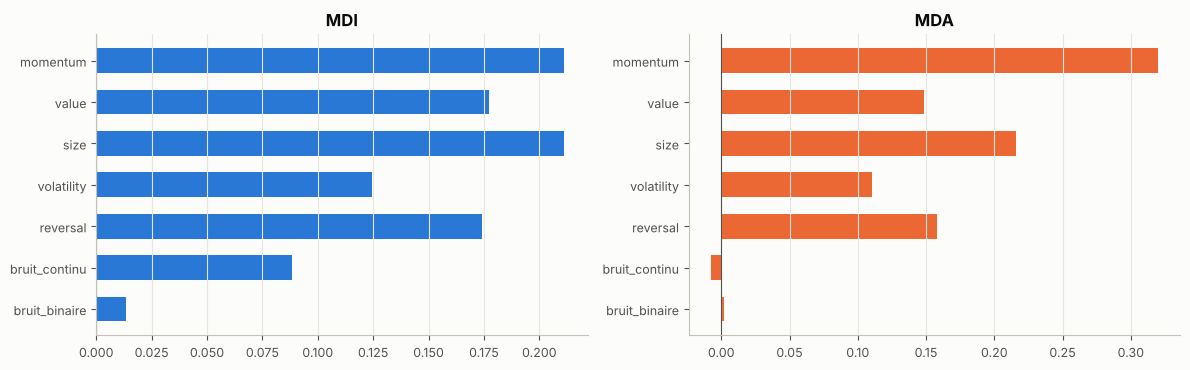

✅ MDI : le bruit continu paraît plus important que le bruit binaire


,MDI,MDA
momentum,0.2112,0.3197
value,0.1774,0.1487
size,0.2111,0.2161
volatility,0.1246,0.1105
reversal,0.1740,0.1581
bruit_continu,0.0882,-0.0075
bruit_binaire,0.0135,0.0021


In [19]:
imp = pd.DataFrame({"MDI": mdi_importance(rf_p), "MDA": mda_importance(rf_p, Xp_tr, yp_tr)}, index=feats)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, c, col in zip(axes, imp.columns, [BLUE, ORANGE]):
    ax.barh(imp.index[::-1], imp[c][::-1], color=col, height=0.6)
    ax.axvline(0, color=INK2, lw=0.8); ax.set_title(c); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
check(imp.loc["bruit_continu", "MDI"] > imp.loc["bruit_binaire", "MDI"], "MDI : le bruit continu paraît plus important que le bruit binaire")
imp

**Questions.**
1. Pourquoi l'OLS passe-t-il à côté d'une partie du signal ? Que faudrait-il ajouter à la régression linéaire pour rattraper la forêt ?
2. Comment expliquez-vous l'importance MDI non nulle de `bruit_continu` ? Pourquoi la MDA est-elle plus fiable pour décider de garder une variable ?
3. Arbre seul, forêt, AdaBoost : lequel choisir pour ce problème ?

> **Corrigé.**
>
> 1. L'effet du momentum est **conditionnel** (seulement si la volatilité est faible) et la taille a un effet en **U** : en moyenne sur l'échantillon, une régression linéaire ne voit qu'une partie du momentum et rien de la taille. Il faudrait construire à la main l'interaction `momentum × 1{vol < médiane}` et le terme `size²` (fonctions de base, TP 6) — possible si on connaît la structure ; la forêt la découvre seule.
> 2. Une variable continue offre des centaines de seuils possibles : l'arbre trouve toujours une coupure qui réduit un peu l'impureté **sur l'échantillon d'apprentissage** (surapprentissage du bruit), et la MDI additionne ces gains. Une variable binaire n'offre qu'un seuil. La MDA mesure la dégradation **hors échantillon** (OOB) quand on casse le lien entre la variable et la cible : ≈ 0 pour du bruit, quel que soit son type. En recherche quantitative, on préfère la MDA (ou des importances calculées sur un échantillon de validation) pour éviter de « découvrir » des facteurs fallacieux.
> 3. Un arbre seul est trop instable (variance). AdaBoost est conçu pour la classification à faible bruit : sa perte exponentielle donne un poids énorme aux points mal classés — ici, presque tous les rendements sont du bruit et AdaBoost sur-apprendrait les valeurs extrêmes. La **forêt** (feuilles larges, beaucoup d'arbres) est robuste au bruit. En pratique, les fonds utilisent forêts et **gradient boosting** (XGBoost, LightGBM) avec une forte régularisation.

## Partie 5 — Synthèse : quel ensemble, quand ?

| Méthode | Apprenant de base | Ce qu'elle réduit | Forces | Faiblesses | Quand l'utiliser |
|---|---|---|---|---|---|
| **Arbre de décision** | — | — | interprétable, rapide, variables hétérogènes (continues + catégorielles), invariant aux transformations monotones | profond : variance forte ; peu profond : biais fort | explication, règles métier, brique des ensembles |
| **Bagging** | arbre profond (biais faible) | la **variance** (moyenne) | parallélisable, OOB gratuit | plancher $\rho\sigma^2$ si arbres corrélés | tout apprenant instable |
| **Forêt aléatoire** | arbre profond + $m<d$ variables par nœud | la variance, en décorrélant ($\rho\downarrow$) | excellentes performances « clé en main », peu d'hyperparamètres, robuste au bruit, OOB, importances | moins interprétable, prédiction plus lente, extrapole mal | **défaut** pour données tabulaires, données bruitées (finance) |
| **AdaBoost** | apprenant faible (souche) | le **biais** (séquentiel) | erreur d'apprentissage → 0 exponentiellement, peu de paramètres | séquentiel, **sensible au bruit et aux outliers** (perte exponentielle), pas d'OOB/MDA | classification avec étiquettes propres |
| *Gradient boosting* (hors cours) | arbres peu profonds | le biais, avec perte quelconque | état de l'art sur données tabulaires | réglage fin (taux d'apprentissage, profondeur, régularisation) | compétitions, production en quant (XGBoost, LightGBM) |